In [1]:
import pandas as pd
import json 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
RESULT_DIR = "/data/Kushal/UniversalRetrieval_data/"

# Multiple Dataset

In [2]:
order = [
    #Popular Representation
    'pipe_serialized',
    'token_serialized',
    'space_serialized',
    "centroid_popular",
    # Data Representation
    'csv',
    'tsv',
    'html',
    'markdown',
    'latex',
    'dict',
    'json',
    'xml',
    "centroid_data",
    # Structural Transformations 
    'shuffled_rows',
    'shuffled_cols',
    'transpose',
    "centroid_structural",
    #Schema Definition Types
    'mschema',
    'macschema',
    'ddl',
    "centroid_schema",
     "centroid_all",
]
'''# Top 5
"tsv_csv_space_serialized_ddl_latex",
"tsv_csv_pipe_serialized_space_serialized_transpose",
"xml_dict_json_pipe_serialized_markdown",
"xml_ddl_latex_html_token_serialized",
# Top 5 All
"csv_tsv_pipe_serialized_space_serialized_xml_latex",'''
category = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized',"centroid_popular"],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            'centroid_data'],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose',
        'centroid_structural'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl',
    'centroid_schema'],
    "All" :['centroid_all'],
    "Top 5": [  "tsv_csv_space_serialized_ddl_latex","tsv_csv_pipe_serialized_space_serialized_transpose","xml_dict_json_pipe_serialized_markdown","xml_ddl_latex_html_token_serialized"],
    "Top 5 All": ["csv_tsv_pipe_serialized_space_serialized_xml_latex"],
}
category_wo_centroid = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized'],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            ],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl'],
    "Top 5": [   "tsv_csv_space_serialized_ddl_latex","tsv_csv_pipe_serialized_space_serialized_transpose","xml_dict_json_pipe_serialized_markdown","xml_ddl_latex_html_token_serialized"],
     "Top 5 All": ["csv_tsv_pipe_serialized_space_serialized_xml_latex"]
}

['miniLM' 'mdbr' 'mpnet' 'bge' 'splade' 'qwen0.6B' 'qwen4B' 'reasonir']
WTQ | Recall@1 by Serialization Method


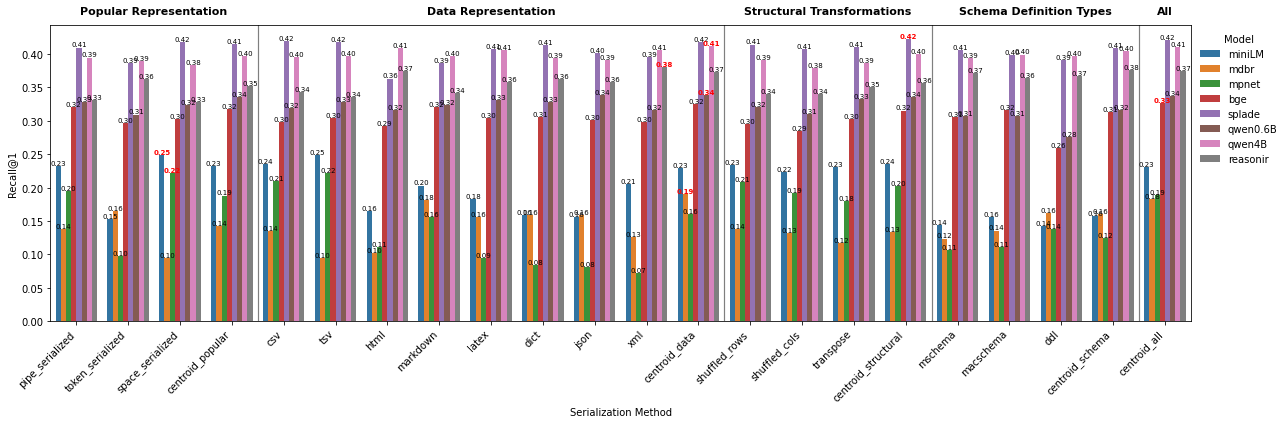

['miniLM' 'mdbr' 'mpnet' 'bge' 'splade' 'qwen0.6B' 'qwen4B' 'reasonir']
WIKISQL | Recall@1 by Serialization Method


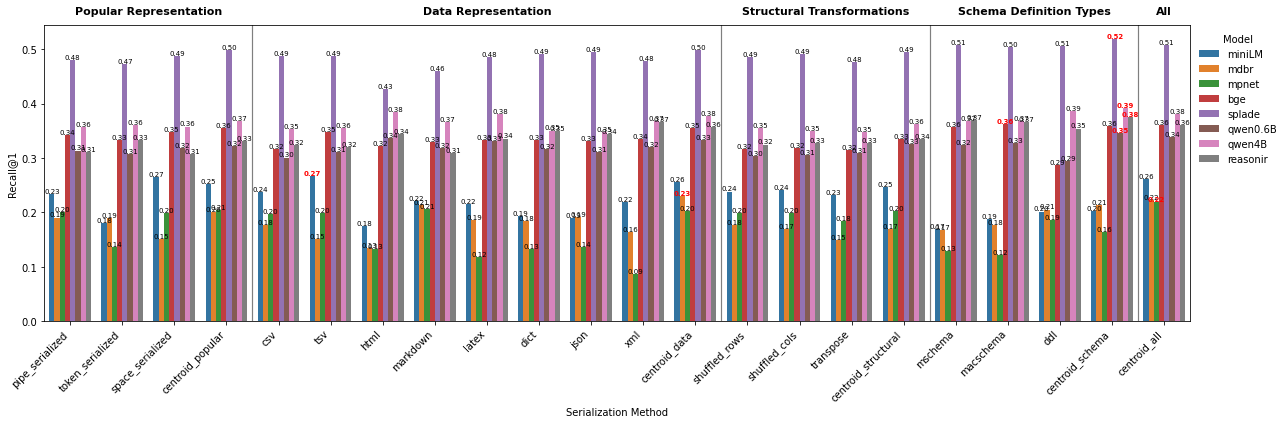

['miniLM' 'mdbr' 'mpnet' 'bge' 'splade' 'qwen0.6B' 'qwen4B' 'reasonir']
NQ | Recall@1 by Serialization Method


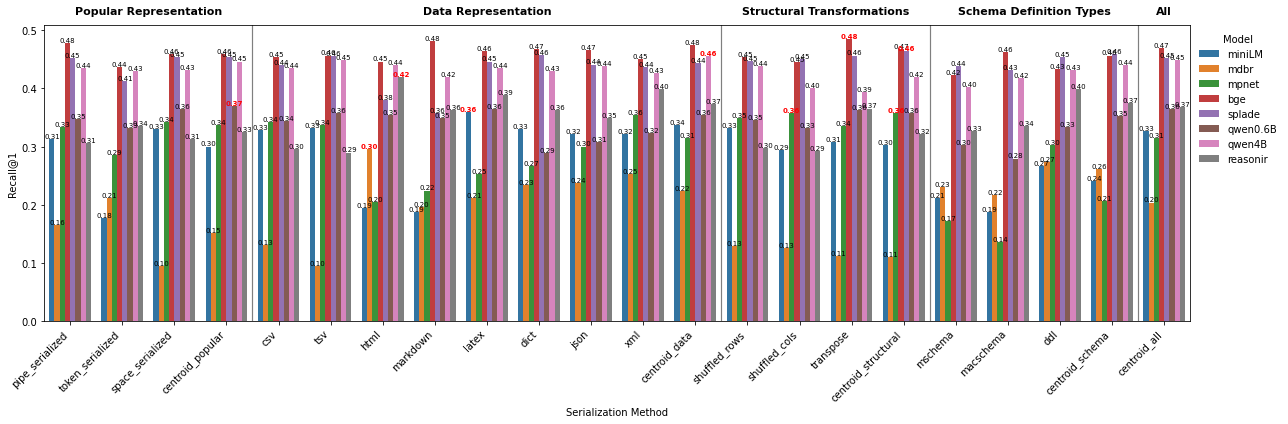

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

base_models =["miniLM", "mdbr", "mpnet", "bge", "splade", "qwen0.6B", "qwen4B", "reasonir"]
'''
| Rank | Model        | Parameters | Embedding size    | Source                                                   |
| ---- | ------------ | ---------- | ----------------- | -------------------------------------------------------- |
| 1    | **miniLM**   | ~22.7M     | **384**           | Qualcomm AI Hub, Hugging Face ([Hugging Face][1])        |
| 2    | **mdbr**     | ~23M       | **768**           | MongoDB / Hugging Face ([Hugging Face][2])               |
| 3    | **mpnet**    | ~109M      | **768**           | Sentence Transformers / Hugging Face ([Hugging Face][3]) |
| 4    | **bge**      | ~109M      | **768**           | BGE / Hugging Face ([Hugging Face][4])                   |
| 5    | **splade**   | ~110M      | **30,522 sparse** | NAVER / Hugging Face ([Hugging Face][5])                 |
| 6    | **qwen0.6B** | ~600M      | **1,024**         | Qwen3 Embedding ([GitHub][6])                            |
| 7    | **qwen4B**   | ~4B        | **2,560**         | Qwen3 Embedding ([GitHub][6])                            |
| 8    | **reasonir** | ~8B        | **4,096**         | ReasonIR / Hugging Face ([Hugging Face][7])              |

[1]: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/blob/main/config.json "config.json · sentence-transformers/all-MiniLM-L6-v2 at main"
[2]: https://huggingface.co/MongoDB/mdbr-leaf-ir "MongoDB/mdbr-leaf-ir · Hugging Face"
[3]: https://huggingface.co/sentence-transformers/all-mpnet-base-v2/blob/main/config.json "config.json · sentence-transformers/all-mpnet-base-v2 at main"
[4]: https://huggingface.co/BAAI/bge-base-en-v1.5/blob/main/config.json "config.json · BAAI/bge-base-en-v1.5 at main"
[5]: https://huggingface.co/naver/splade-cocondenser-ensembledistil "naver/splade-cocondenser-ensembledistil · Hugging Face"
[6]: https://github.com/QwenLM/Qwen3-Embedding/blob/main/README.md "Qwen3-Embedding/README.md at main · QwenLM/Qwen3-Embedding · GitHub"
[7]: https://huggingface.co/reasonir/ReasonIR-8B/blob/main/config.json "config.json · reasonir/ReasonIR-8B at main"

'''
palette = dict(zip(base_models, sns.color_palette("tab10", n_colors=len(base_models))))

for topk in [1]:
    for dataset in ["WTQ", "WIKISQL", "NQ"]:
        df_list = []

        for model in base_models:
            for representative in order:
                representative_file = representative.replace("centroid", "centroid_centroid") if "centroid_all" not in representative else representative
                fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative_file}_gold_rank_per_question.csv"

                if not Path(fpath).exists():
                    print(f"[skip] {fpath}")
                    continue

                df_temp = pd.read_csv(fpath)[["model", "dataset", "question_id", "rank"]].copy()
                df_temp["Representation"] = representative
                df_temp[f"recall@{topk}"] = (df_temp["rank"] <= topk).astype(int)
                df_temp[f"ndcg@{topk}"] = np.where(df_temp["rank"] <= topk, 1 / np.log2(df_temp["rank"] + 1), 0.0)
                df_list.append(df_temp)

        df = pd.concat(df_list, ignore_index=True)
        print(df["model"].unique())

        plt.figure(figsize=(18, 6))
        ax = sns.barplot(data=df, x="Representation", y=f"recall@{topk}", hue="model", order=order, hue_order=base_models, palette=palette, errorbar=None)

        categories_in_order = ["Popular Representation", "Data Representation", "Structural Transformations", "Schema Definition Types", "All"]
        category_sizes = [len(category[x]) for x in categories_in_order]

        starts = np.cumsum([0] + category_sizes[:-1])
        ends = np.cumsum(category_sizes)
        centers = (starts + ends - 1) / 2

        for boundary in ends[:-1]:
            ax.axvline(boundary - 0.5, color="black", linestyle="-", linewidth=1.2, alpha=0.5)

        ymax = ax.get_ylim()[1]
        for center, label in zip(centers, categories_in_order):
            ax.text(center, ymax * 1.03, label, ha="center", va="bottom", fontsize=11, fontweight="bold")

        plt.ylabel(f"Recall@{topk}")
        plt.xlabel("Serialization Method")
        print(f"{dataset} | Recall@{topk} by Serialization Method")
        plt.xticks(rotation=45, ha="right")

        mean_scores = df.groupby(["model", "Representation"])[f"recall@{topk}"].mean().unstack()
        best_scores = mean_scores.max(axis=1)

        for model, container in zip(base_models, ax.containers):
            for rep, bar in zip(order, container):
                height = bar.get_height()
                if np.isnan(height): continue
                is_best = np.isclose(height, best_scores.loc[model])
                ax.text(bar.get_x() + bar.get_width()/2, height, f"{height:.2f}", ha="center", va="bottom",
                        fontsize=7, fontweight="bold" if is_best else "normal",
                        color="red" if is_best else "black")

        ax.legend(title="Model", bbox_to_anchor=(1, 1), loc="upper left", frameon=False)
        plt.subplots_adjust(top=0.80)
        plt.tight_layout()
        plt.show()

In [4]:
all_summary = []
subset_order = ["pipe_serialized", "token_serialized", "space_serialized", "csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml", "shuffled_rows", "shuffled_cols", "transpose", "mschema", "macschema", "ddl", "centroid_all"]

for recall_value in [1]:
    for dataset in ["WTQ", "WIKISQL", "NQ"]:
        df_list = []

        for model in base_models:
            for representative in subset_order:
                representative_file = representative.replace("centroid", "centroid_centroid") if "centroid_all" not in representative else representative
                fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative_file}_gold_rank_per_question.csv"

                if not Path(fpath).exists():
                    print(f"[skip] {fpath}")
                    continue

                temp = pd.read_csv(fpath)[["model", "dataset", "question_id", "rank"]].copy()
                temp["Representation"] = representative
                temp["Model"] = model
                temp["Dataset"] = dataset
                temp[f"recall@{recall_value}"] = (temp["rank"] <= recall_value).astype(int)
                df_list.append(temp)

        df = pd.concat(df_list, ignore_index=True)
        metric = f"recall@{recall_value}"

        summary = df.groupby(["Dataset", "Model", "Representation"])[metric].agg(["mean", "std"]).reset_index()
        summary["mean_std"] = summary.apply(lambda row: f"{row['mean']:.2f}", axis=1)
        all_summary.append(summary)

final_summary = pd.concat(all_summary, ignore_index=True)

latex_table = final_summary.pivot(index=["Dataset", "Model"], columns="Representation", values="mean_std").reindex(columns=subset_order)
latex_table = latex_table.reindex(index=pd.MultiIndex.from_product([["WTQ", "WIKISQL", "NQ"], base_models], names=["Dataset", "Model"]))

print(latex_table.to_latex(escape=False, na_rep="", multirow=True, caption=f"Results for recall@{recall_value}", label=f"tab:recall_{recall_value}_by_dataset_model", column_format="ll" + "c" * len(latex_table.columns)))

\begin{table}
\caption{Results for recall@1}
\label{tab:recall_1_by_dataset_model}
\begin{tabular}{llcccccccccccccccccc}
\toprule
 & Representation & pipe_serialized & token_serialized & space_serialized & csv & tsv & html & markdown & latex & dict & json & xml & shuffled_rows & shuffled_cols & transpose & mschema & macschema & ddl & centroid_all \\
Dataset & Model &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{8}{*}{WTQ} & miniLM & 0.23 & 0.15 & 0.25 & 0.24 & 0.25 & 0.16 & 0.20 & 0.18 & 0.16 & 0.16 & 0.21 & 0.23 & 0.22 & 0.23 & 0.14 & 0.16 & 0.14 & 0.23 \\
 & mdbr & 0.14 & 0.16 & 0.10 & 0.14 & 0.10 & 0.10 & 0.18 & 0.16 & 0.16 & 0.16 & 0.13 & 0.14 & 0.13 & 0.12 & 0.12 & 0.14 & 0.16 & 0.18 \\
 & mpnet & 0.20 & 0.10 & 0.22 & 0.21 & 0.22 & 0.11 & 0.16 & 0.09 & 0.08 & 0.08 & 0.07 & 0.21 & 0.19 & 0.18 & 0.11 & 0.11 & 0.14 & 0.19 \\
 & bge & 0.32 & 0.30 & 0.30 & 0.30 & 0.30 & 0.29 & 0.32 & 0.30 & 0.31 & 0.30 & 0.30 & 0.30 & 0.29 & 0.30 & 0.31 & 0.32 & 0.26 & 0

In [5]:
metric = f"recall@{recall_value}"

for dataset in  ["WTQ", "WIKISQL", "NQ"]:
    df_list = []

    for model in ["splade", "qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]:
        for representative in order:
            representative_file = representative.replace("centroid", "centroid_centroid") if "centroid_all" not in representative else representative
            fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative_file}_gold_rank_per_question.csv"

            if not Path(fpath).exists():
                print(f"[skip] {fpath}")
                continue

            temp = pd.read_csv(fpath)[["model", "dataset", "question_id", "rank"]].copy()
            temp["Representation"] = representative
            temp["Model"] = model
            temp[metric] = (temp["rank"] <= recall_value).astype(int)
            df_list.append(temp)

    df = pd.concat(df_list, ignore_index=True)

    # Compute retrieval performance for each model and representation
    rep_scores = df.groupby(["Model", "Representation"], as_index=False)[metric].mean()

    # Keep representations belonging to each category
    cat_rows = []
    for cat, reps in category_wo_centroid.items():
        tmp = rep_scores[rep_scores["Representation"].isin(reps)].copy()
        tmp["Category"] = cat
        cat_rows.append(tmp)

    df_cat = pd.concat(cat_rows, ignore_index=True)

    # Per-model fluctuation across representations within each category
    stats = df_cat.groupby(["Model", "Category"], as_index=False).agg(
        n_reps=("Representation", "nunique"),
        mean=(metric, "mean"),
        sd=(metric, "std"),
        min_val=(metric, "min"),
        max_val=(metric, "max")
    )
    stats["range"] = stats["max_val"] - stats["min_val"]

    print(f"\n{dataset} | Per-model fluctuation within category")
    for model in stats["Model"].unique():
        print(f"\n=== {model} ===")
        print(stats[stats["Model"] == model].sort_values("Category")[["Category", "n_reps", "mean", "sd", "range", "min_val", "max_val"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    # Model disagreement for each representation
    model_disagreement = df_cat.groupby(["Category", "Representation"], as_index=False).agg(sd_across_models=(metric, "std"))

    print(f"\n{dataset} | SD across models for each Category × Representation")
    print(model_disagreement.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    # All non-centroid representations
    all_reps = sorted({r for reps in category_wo_centroid.values() for r in reps})
    df_all = rep_scores[rep_scores["Representation"].isin(all_reps)].copy()

    overall = df_all.groupby("Model", as_index=False).agg(
        n_reps=("Representation", "nunique"),
        mean=(metric, "mean"),
        sd=(metric, "std"),
        min_val=(metric, "min"),
        max_val=(metric, "max")
    )
    overall["range"] = overall["max_val"] - overall["min_val"]

    print(f"\n{dataset} | Overall per-model fluctuation across all non-centroid representations")
    print(overall[["Model", "n_reps", "mean", "sd", "range", "min_val", "max_val"]].sort_values("Model").to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print("+++++" * 100)


WTQ | Per-model fluctuation within category

=== bge ===
                  Category  n_reps   mean     sd  range  min_val  max_val
       Data Representation       8 0.3030 0.0083 0.0286   0.2919   0.3205
    Popular Representation       3 0.3067 0.0130 0.0250   0.2962   0.3212
   Schema Definition Types       3 0.2935 0.0303 0.0571   0.2590   0.3162
Structural Transformations       3 0.2944 0.0087 0.0174   0.2852   0.3026

=== mdbr ===
                  Category  n_reps   mean     sd  range  min_val  max_val
       Data Representation       8 0.1391 0.0301 0.0860   0.0952   0.1812
    Popular Representation       3 0.1324 0.0348 0.0690   0.0952   0.1643
   Schema Definition Types       3 0.1407 0.0199 0.0388   0.1238   0.1626
Structural Transformations       3 0.1293 0.0105 0.0202   0.1176   0.1379

=== miniLM ===
                  Category  n_reps   mean     sd  range  min_val  max_val
       Data Representation       8 0.1943 0.0352 0.0933   0.1552   0.2486
    Popular Representati

## Check standard deviation within representation

In [6]:
metric = f"recall@{recall_value}"

for dataset in ["WTQ", "WIKISQL", "NQ"]:
    df_list = []

    for model in ["splade", "qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]:
        for representative in order:
            representative_file = representative.replace("centroid", "centroid_centroid") if "centroid_all" not in representative else representative
            fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative_file}_gold_rank_per_question.csv"

            if not Path(fpath).exists():
                print(f"[skip] {fpath}")
                continue

            temp = pd.read_csv(fpath)[["model", "dataset", "question_id", "rank"]].copy()
            temp["Representation"] = representative
            temp["Model"] = model
            temp[metric] = (temp["rank"] <= recall_value).astype(int)
            df_list.append(temp)

    df = pd.concat(df_list, ignore_index=True)

    # Compute retrieval performance for each model and representation
    rep_scores = df.groupby(["Model", "Representation"], as_index=False)[metric].mean()

    # Keep representations belonging to each category
    cat_rows = []
    for cat, reps in category_wo_centroid.items():
        tmp = rep_scores[rep_scores["Representation"].isin(reps)].copy()
        tmp["Category"] = cat
        cat_rows.append(tmp)

    df_cat = pd.concat(cat_rows, ignore_index=True)

    # Per-model fluctuation across representations within each category
    stats = df_cat.groupby(["Model", "Category"], as_index=False).agg(
        n_reps=("Representation", "nunique"),
        mean=(metric, "mean"),
        sd=(metric, "std"),
        min_val=(metric, "min"),
        max_val=(metric, "max")
    )
    stats["range"] = stats["max_val"] - stats["min_val"]

    print(f"\n{dataset} | Per-model fluctuation within category")
    for model in stats["Model"].unique():
        print(f"\n=== {model} ===")
        print(stats[stats["Model"] == model].sort_values("Category")[["Category", "n_reps", "mean", "sd", "range", "min_val", "max_val"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    # Model disagreement for each representation
    model_disagreement = df_cat.groupby(["Category", "Representation"], as_index=False).agg(sd_across_models=(metric, "std"))

    print(f"\n{dataset} | SD across models for each Category × Representation")
    print(model_disagreement.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    # All non-centroid representations
    all_reps = sorted({r for reps in category_wo_centroid.values() for r in reps})
    df_all = rep_scores[rep_scores["Representation"].isin(all_reps)].copy()

    overall = df_all.groupby("Model", as_index=False).agg(
        n_reps=("Representation", "nunique"),
        mean=(metric, "mean"),
        sd=(metric, "std"),
        min_val=(metric, "min"),
        max_val=(metric, "max")
    )
    overall["range"] = overall["max_val"] - overall["min_val"]

    print(f"\n{dataset} | Overall per-model fluctuation across all non-centroid representations")
    print(overall[["Model", "n_reps", "mean", "sd", "range", "min_val", "max_val"]].sort_values("Model").to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print("+++++" * 100)


WTQ | Per-model fluctuation within category

=== bge ===
                  Category  n_reps   mean     sd  range  min_val  max_val
       Data Representation       8 0.3030 0.0083 0.0286   0.2919   0.3205
    Popular Representation       3 0.3067 0.0130 0.0250   0.2962   0.3212
   Schema Definition Types       3 0.2935 0.0303 0.0571   0.2590   0.3162
Structural Transformations       3 0.2944 0.0087 0.0174   0.2852   0.3026

=== mdbr ===
                  Category  n_reps   mean     sd  range  min_val  max_val
       Data Representation       8 0.1391 0.0301 0.0860   0.0952   0.1812
    Popular Representation       3 0.1324 0.0348 0.0690   0.0952   0.1643
   Schema Definition Types       3 0.1407 0.0199 0.0388   0.1238   0.1626
Structural Transformations       3 0.1293 0.0105 0.0202   0.1176   0.1379

=== miniLM ===
                  Category  n_reps   mean     sd  range  min_val  max_val
       Data Representation       8 0.1943 0.0352 0.0933   0.1552   0.2486
    Popular Representati

# Compare Representation Variation

In [7]:
topk_list = [1,5,10]
category = {
    "Popular Representation": ["pipe_serialized", "token_serialized", "space_serialized", "centroid_popular"],
    "Data Representation": ["csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml", "centroid_data"],
    "Structural Transformations": ["shuffled_rows", "shuffled_cols", "transpose", "centroid_structural"],
    "Schema and Definition Types": ["mschema", "macschema", "ddl", "centroid_schema"],
    "All": ["pipe_serialized", "token_serialized", "space_serialized", "csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml", "shuffled_rows", "shuffled_cols", "transpose", "mschema", "macschema", "ddl", "centroid_all"]
}

category_wo_centroid = {
    "Popular Representation": ["pipe_serialized", "token_serialized", "space_serialized"],
    "Data Representation": ["csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml"],
    "Structural Transformations": ["shuffled_rows", "shuffled_cols", "transpose"],
    "Schema and Definition Types": ["mschema", "macschema", "ddl"],
    "All": ["pipe_serialized", "token_serialized", "space_serialized", "csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml", "shuffled_rows", "shuffled_cols", "transpose", "mschema", "macschema", "ddl"]
}

representation = ["pipe_serialized", "token_serialized", "space_serialized", "centroid_popular", "csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml", "centroid_data", "shuffled_rows", "shuffled_cols", "transpose", "centroid_structural", "mschema", "macschema", "ddl", "centroid_schema", "centroid_all"]

df_list = []

for dataset in ["WTQ", "WIKISQL", "NQ"]:
    for model in ["splade", "qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]:
        for representative in representation:
            representative_file = representative.replace("centroid", "centroid_centroid") if "centroid_all" not in representative else representative
            fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative_file}_gold_rank_per_question.csv"

            if not Path(fpath).exists():
                print(f"[skip] {fpath}")
                continue

            temp = pd.read_csv(fpath)[["model", "dataset", "question_id", "rank"]].copy()
            temp["Representation"] = representative
            temp["Model"] = model
            temp["Dataset"] = dataset

            for topk in topk_list:
                temp[f"recall@{topk}"] = (temp["rank"] <= topk).astype(int)
                temp[f"ndcg@{topk}"] = np.where(temp["rank"] <= topk, 1 / np.log2(temp["rank"] + 1), 0.0)

            df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

def get_category(rep):
    if rep == "centroid_all":
        return "All"
    for cat, reps in category.items():
        if cat != "All" and rep in reps:
            return cat
    return None

df["Category"] = df["Representation"].apply(get_category)

In [8]:
metric = "recall@1"
df["IsCentroid"] = df["Representation"].apply(lambda x: True if 'centroid' in x else False)
df_wo_centroid = df[~df["IsCentroid"]].copy()
df_wo_centroid["rank"] = (
    df_wo_centroid.groupby(["Model", "Dataset"])[metric]
      .rank(ascending=False, method="average")
)
df_wo_centroid =df_wo_centroid.sort_values(["Model", "Dataset","rank"])

## Variation of the performance

Per Dataset x Model variation across representation means
Dataset    Model      std  min_val  max_val     mean  n_reps    range
     NQ      bge 0.012805 0.825052 0.874741 0.851541      17 0.049689
     NQ     mdbr 0.122349 0.305383 0.654244 0.492754      17 0.348861
     NQ   miniLM 0.084582 0.525880 0.753623 0.662221      17 0.227743
     NQ    mpnet 0.113685 0.468944 0.814700 0.705821      17 0.345756
     NQ qwen0.6B 0.023198 0.694617 0.774327 0.728718      17 0.079710
     NQ   qwen4B 0.017332 0.798137 0.853002 0.834429      17 0.054865
     NQ reasonir 0.033653 0.738095 0.837474 0.783887      17 0.099379
     NQ   splade 0.027556 0.773292 0.867495 0.837535      17 0.094203
WIKISQL      bge 0.024013 0.554352 0.644162 0.600276      17 0.089810
WIKISQL     mdbr 0.042618 0.304887 0.436768 0.374306      17 0.131881
WIKISQL   miniLM 0.037186 0.404459 0.530231 0.460767      17 0.125772
WIKISQL    mpnet 0.053487 0.266028 0.464290 0.393545      17 0.198262
WIKISQL qwen0.6B 0.012886 0.5799

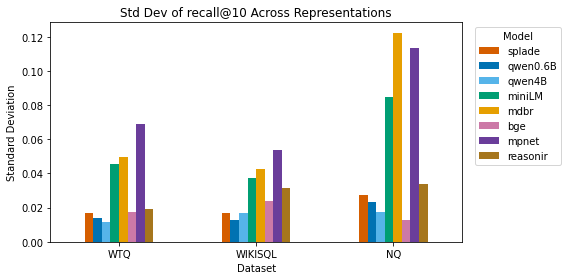

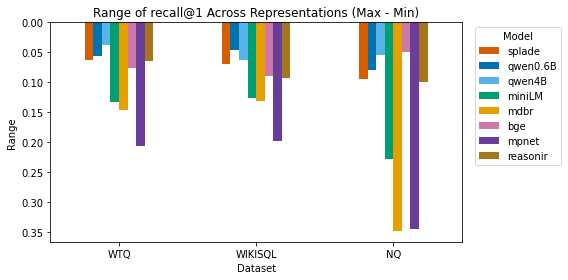


Ranking by avg_range_across_models (higher = more variation):
Dataset  avg_std_across_models  avg_range_across_models
     NQ               0.054395                 0.162526
WIKISQL               0.029407                 0.102091
    WTQ               0.030373                 0.097649


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

metric = 'recall@10'
shade_levels = {
    "splade": 0.85,
    "qwen0.6B": 0.75,
    "qwen4B": 0.85,
    "miniLM": 0.80,
    "mdbr": 0.75,
    "bge": 0.75,
    "mpnet": 0.75,
    "reasonir": 0.80,
}

palette = {
    "splade": "#D55E00",
    "qwen0.6B": "#0072B2",
    "qwen4B": "#56B4E9",
    "miniLM": "#009E73",
    "mdbr": "#E69F00",
    "bge": "#CC79A7",
    "mpnet": "#6A3D9A",
    "reasonir": "#A6761D",
}

base_models = ["splade", "qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]
datasets = ["WTQ", "WIKISQL", "NQ"]
# -----------------------------
# 1) Keep only non-centroid rows
# -----------------------------
df = df_wo_centroid.copy()

# If df_wo_centroid already excludes centroid, this is harmless.
if 'IsCentroid' in df.columns:
    df = df[df['IsCentroid'] == False].copy()

# Optional: exclude combo rows if they exist in this df
# (You said this df is "wo centroid", but combos can still appear)
if 'combo_reps' in df.columns:
    df = df[df['combo_reps'].isna()].copy()

# -----------------------------
# 2) Compute variation per Dataset x Model
# -----------------------------
# Mean recall for each Dataset x Model x Representation
rep_means = (
    df.groupby(["Dataset", "Model", "Representation"], as_index=False)[metric]
      .mean()
      .rename(columns={metric: "rep_mean"})
)

# Variation across representation-level mean recall values
variation = (
    rep_means.groupby(["Dataset", "Model"])["rep_mean"]
             .agg(std="std", min_val="min", max_val="max", mean="mean", n_reps="count")
             .reset_index()
)

variation["range"] = variation["max_val"] - variation["min_val"]

print("Per Dataset x Model variation across representation means")
print(variation.sort_values(["Dataset", "Model"]).to_string(index=False))

# -----------------------------
# 3) Dataset-level summary
#    (average variation across models)
# -----------------------------
dataset_summary = (
    variation.groupby('Dataset')[['std', 'range']]
             .mean()
             .reset_index()
             .rename(columns={
                 'std': 'avg_std_across_models',
                 'range': 'avg_range_across_models'
             })
)

print("\nDataset-level summary:")
print(dataset_summary.sort_values('avg_range_across_models', ascending=False).to_string(index=False))

# -----------------------------
# 4) Plot standard deviation
# -----------------------------
std_pivot = variation.pivot(index='Dataset', columns='Model', values='std')
std_pivot = std_pivot.reindex(index=datasets,columns=base_models)
ax = std_pivot.plot(kind='bar', figsize=(8, 4), rot=0,color = palette)
ax.set_title(f'Std Dev of {metric} Across Representations')
ax.set_xlabel('Dataset')
ax.set_ylabel('Standard Deviation')
ax.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# -----------------------------
# 5) Plot range (max - min)
# -----------------------------
range_pivot = variation.pivot(index='Dataset', columns='Model', values='range')
range_pivot = range_pivot.reindex(index=datasets,columns=base_models)

ax = range_pivot.plot(kind='bar', figsize=(8, 4), rot=0,color = palette)
ax.set_title('Range of recall@1 Across Representations (Max - Min)')
ax.set_xlabel('Dataset')
ax.set_ylabel('Range')
ax.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# -----------------------------
# 6) Single-number view for your claim
# -----------------------------
print("\nRanking by avg_range_across_models (higher = more variation):")
print(dataset_summary.sort_values('avg_range_across_models', ascending=False).to_string(index=False))


In [10]:
print(variation)

    Dataset     Model       std   min_val   max_val      mean  n_reps  \
0        NQ       bge  0.012805  0.825052  0.874741  0.851541      17   
1        NQ      mdbr  0.122349  0.305383  0.654244  0.492754      17   
2        NQ    miniLM  0.084582  0.525880  0.753623  0.662221      17   
3        NQ     mpnet  0.113685  0.468944  0.814700  0.705821      17   
4        NQ  qwen0.6B  0.023198  0.694617  0.774327  0.728718      17   
5        NQ    qwen4B  0.017332  0.798137  0.853002  0.834429      17   
6        NQ  reasonir  0.033653  0.738095  0.837474  0.783887      17   
7        NQ    splade  0.027556  0.773292  0.867495  0.837535      17   
8   WIKISQL       bge  0.024013  0.554352  0.644162  0.600276      17   
9   WIKISQL      mdbr  0.042618  0.304887  0.436768  0.374306      17   
10  WIKISQL    miniLM  0.037186  0.404459  0.530231  0.460767      17   
11  WIKISQL     mpnet  0.053487  0.266028  0.464290  0.393545      17   
12  WIKISQL  qwen0.6B  0.012886  0.579922  0.625583

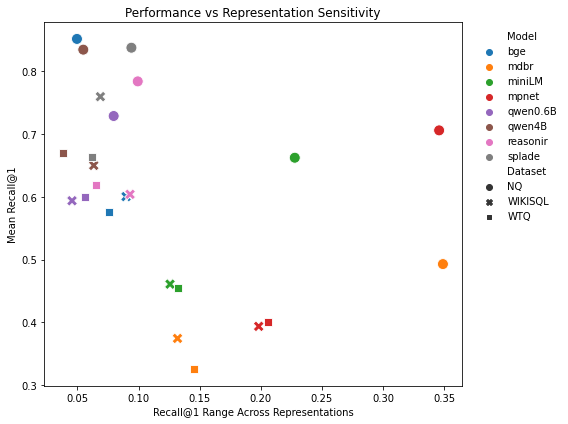

In [11]:
plt.figure(figsize=(8, 6))

ax = sns.scatterplot(
    data=variation,
    x="range", y="mean",
    hue="Model", style="Dataset",
    s=120
)

plt.xlabel("Recall@1 Range Across Representations")
plt.ylabel("Mean Recall@1")
plt.title("Performance vs Representation Sensitivity")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

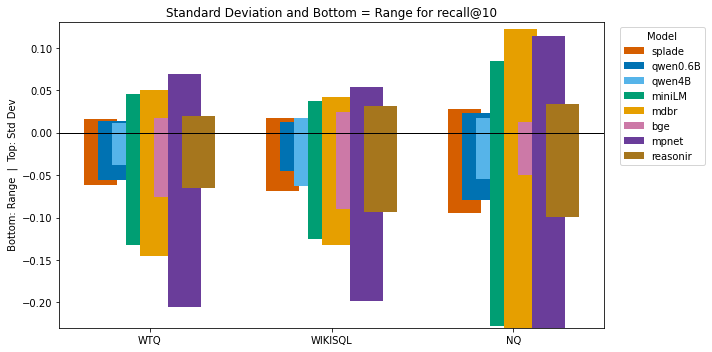

In [12]:
import numpy as np
import matplotlib.pyplot as plt

std_pivot = variation.pivot(index='Dataset', columns='Model', values='std')
std_pivot = std_pivot.reindex(index=datasets, columns=base_models)

range_pivot = variation.pivot(index='Dataset', columns='Model', values='range')
range_pivot = range_pivot.reindex(index=datasets, columns=base_models)

x = np.arange(len(datasets))
width = 0.18
offsets = np.linspace(-1.5 * width, 1.5 * width, len(base_models))

fig, ax = plt.subplots(figsize=(10, 5))

for i, model in enumerate(base_models):
    ax.bar(
        x + offsets[i],
        std_pivot[model],
        width=width,
        color=palette[model],
        label=f'{model} std'
    )
    ax.bar(
        x + offsets[i],
        -range_pivot[model],
        width=width,
        color=palette[model],
        label=f'{model} range' if i == 0 else None
    )
ymax_new = 0.2
ax.axhline(0, color='black', linewidth=1)
ax.set_ylim(-ymax_new * 1.15, ymax_new * 1.15-0.1)
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel(' Bottom: Range  |  Top: Std Dev')
ax.set_title(f'Standard Deviation and Bottom = Range for {metric}')

# Cleaner legend: one for models, one note in caption/title is usually better
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
unique = {d:unique[d+" std"] for d in base_models}
ax.legend(unique.values(), unique.keys(), title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')


plt.tight_layout()
plt.show()

## Best representation by model?

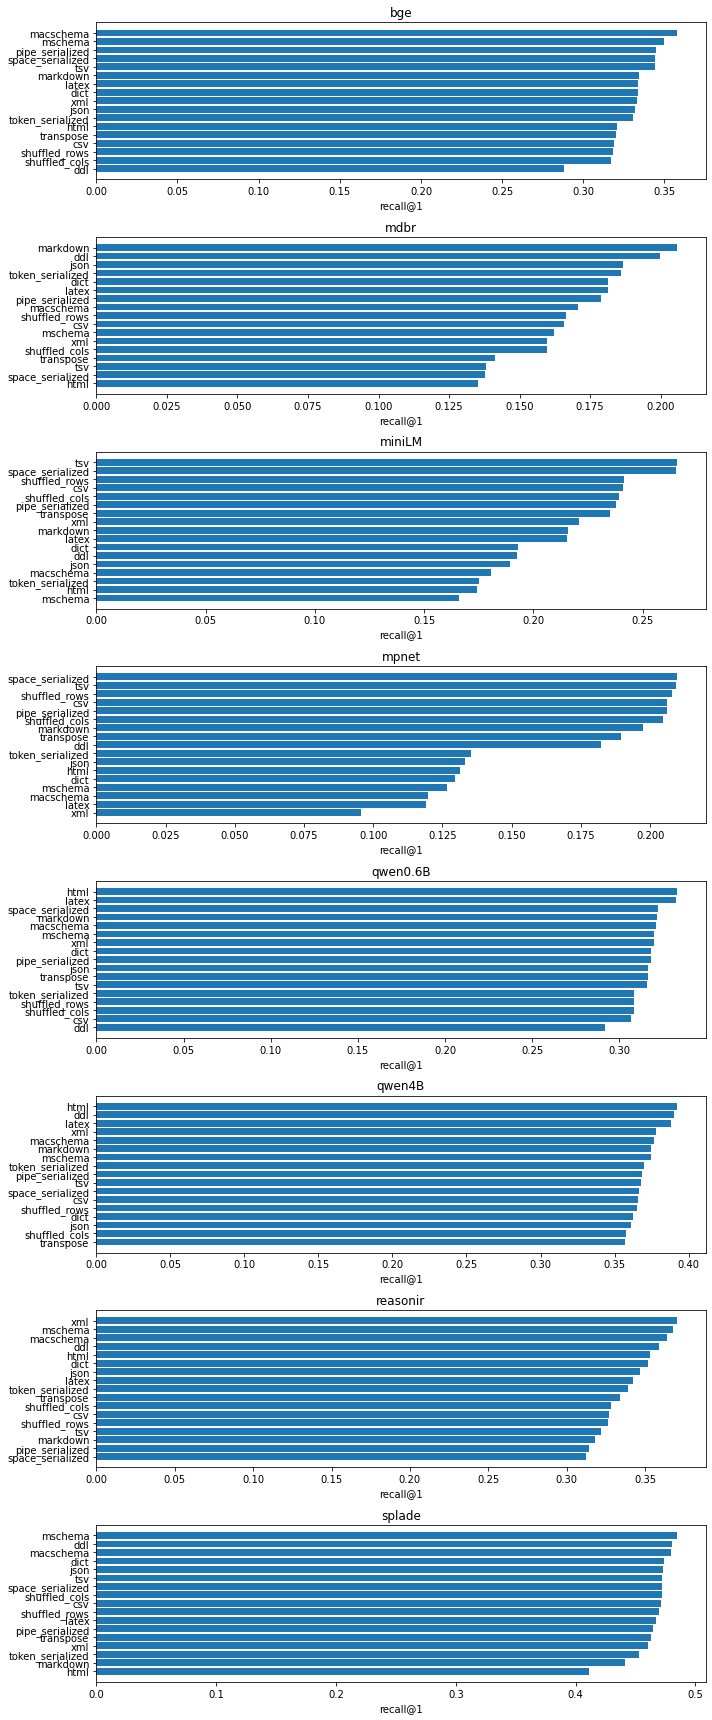

In [13]:
import matplotlib.pyplot as plt

metric = "recall@1"

avg = (
    df_wo_centroid.groupby(["Model", "Representation"], as_index=False)[metric]
      .mean()
)
avg["rank"] = (
    avg.groupby("Model")[metric]
       .rank(method="first", ascending=False)
)
avg = avg.sort_values(["Model", "rank"])


models = avg["Model"].unique()
n_models = len(models)

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(10, 3 * n_models),
    sharex=False
)

if n_models == 1:
    axes = [axes]

for ax, model in zip(axes, models):
    sub = avg[avg["Model"] == model]

    ax.barh(
        sub["Representation"],
        sub[metric]
    )

    ax.invert_yaxis()  # best at top
    ax.set_title(model)
    ax.set_xlabel(metric)

plt.tight_layout()
plt.show()


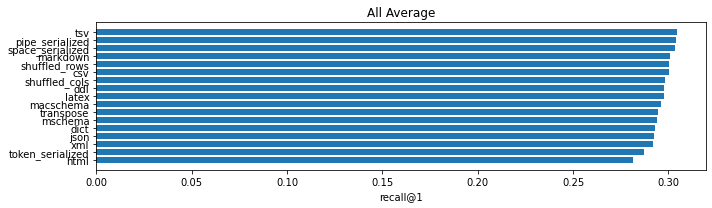

In [14]:
import matplotlib.pyplot as plt

metric = "recall@1"

avg = (
    df_wo_centroid.groupby(["Representation"], as_index=False)[metric]
      .mean()
)
avg["rank"] = (
    avg[metric]
       .rank(method="first", ascending=False)
)
avg = avg.sort_values(["rank"])


fig, axes = plt.subplots(
    1, 1,
    figsize=(10, 3),
)

axes = [axes]

for ax in axes:
    sub = avg

    ax.barh(
        sub["Representation"],
        sub[metric]
    )

    ax.invert_yaxis()  # best at top
    ax.set_title("All Average")
    ax.set_xlabel(metric)

plt.tight_layout()
plt.show()


# By how much does the rank vary when I change representation?

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt



rank_stats = df_wo_centroid["rank"].agg(["min", "max", "std"])
rank_stats

min      1553.500000
max    200225.000000
std     69490.349441
Name: rank, dtype: float64

# Which representations are consistently performing better?

In [16]:
print(df["Dataset"].unique())
print(df["Model"].unique())

['NQ' 'WIKISQL' 'WTQ']
['bge' 'mdbr' 'miniLM' 'mpnet' 'qwen0.6B' 'qwen4B' 'reasonir' 'splade']


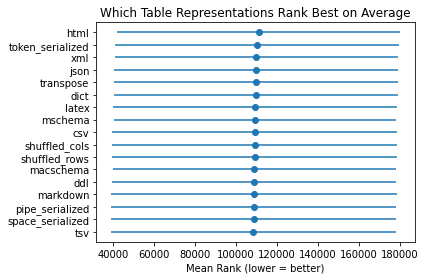

In [17]:
rep_rank = (
    df_wo_centroid
    .groupby("Representation")["rank"]
    .agg(["mean", "std"])
    .reset_index()
    .sort_values("mean")
)

plt.figure(figsize=(6, 4))
plt.errorbar(
    rep_rank["mean"],
    rep_rank["Representation"],
    xerr=rep_rank["std"],
    fmt="o"
)

plt.xlabel("Mean Rank (lower = better)")
plt.ylabel("")
plt.title("Which Table Representations Rank Best on Average")
plt.tight_layout()
plt.show()


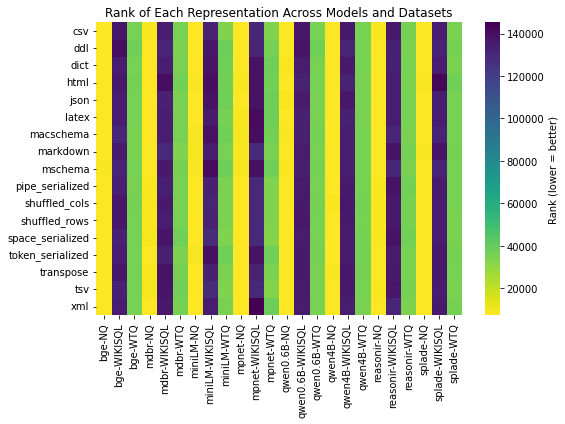

In [18]:
heat_df = (
    df_wo_centroid
    .pivot_table(
        index="Representation",
        columns=["Model", "Dataset"],
        values="rank"
    )
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    heat_df,
    cmap="viridis_r",
    annot=False,
    cbar_kws={"label": "Rank (lower = better)"}
)

plt.title("Rank of Each Representation Across Models and Datasets")
plt.ylabel("")
plt.xlabel("")
plt.tight_layout()
plt.show()

